# 01. Аудит данных и EDA: определение позитивного сигнала

Цель: понять, что лежит в `user_anime_rates`, и **сравнить кандидатные определения позитива** до построения train/test.

## Схема данных

![ER-диаграмма датасета](../docs/ER.drawio.png)

Описание таблиц и ограничений: [dataset_design.md](../docs/dataset_design.md). Внешние ключи проверяются скриптом `src/build_dataset.py`, CSV их не хранит.


## Загрузка данных
Читаем из канонических таблиц только нужные колонки: оценки пользователей (`rates`) и краткий каталог (`anime`). Тяжёлые колонки (`text`, `description`) пропускаем, чтобы не тратить память. Колонки времени переводим в даты с `format="mixed"`, потому что в файле два формата времени.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/processed/shikimori_v1")

rates = pd.read_csv(
    DATA / "user_anime_rates.csv",
    usecols=["rate_id", "user_id", "anime_id", "score", "status", "episodes", "rewatches", "created_at", "updated_at"],
)
anime = pd.read_csv(
    DATA / "anime.csv",
    usecols=["anime_id", "name", "kind", "status", "episodes", "score", "aired_on"],
)
for col in ["created_at", "updated_at"]:
    rates[col] = pd.to_datetime(rates[col], utc=True, format="mixed")

rates.shape, anime.shape, rates.user_id.nunique(), rates.anime_id.nunique()

((694673, 9), (30133, 7), 1996, 29711)

## 1. Статусы и оценки

Посчитаем сколько записей в каждом статусею.

`status` — это состояние аниме в списке пользователя (`completed`, `planned`, `dropped`…). Считаем, как часто встречается каждое значение. Смотрим, нет ли пропусков и какой статус преобладает: от этого зависит, из чего вообще можно строить позитивы.

In [2]:
rates.status.value_counts(dropna=False)

status
completed     429663
planned       198850
dropped        31515
watching       19554
on_hold        14234
rewatching       857
Name: count, dtype: int64

Для каждого статуса считаем:
- сколько строк,
- какая доля из них со `score=0` (то есть без оценки)
- сколько серий в среднем просмотрено (медиана `episodes`).

In [3]:
# Доля score=0 внутри каждого статуса и средний прогресс просмотра
g = rates.assign(no_score=rates.score.eq(0)).groupby("status")
g.agg(rows=("rate_id", "size"), share_no_score=("no_score", "mean"), median_episodes=("episodes", "median"))

,rows,share_no_score,median_episodes
status,,,
completed,429663,0.499710,12.0
dropped,31515,0.855561,0.0
on_hold,14234,0.950049,0.0
planned,198850,0.985386,0.0
rewatching,857,0.707118,0.0
watching,19554,0.890304,0.0


`score=0` — это не «плохая оценка», а «человек не оценивал»: например, у `planned` почти все оценки нулевые, у `completed` примерно половина.

Посмотрим какие оценки ставят в каждом статусе.

Нас интересует, где ставят высокие и низкие оценки: например, оценки у `dropped` (бросил) и `planned` (ещё не смотрел) могут выглядеть странно.

In [4]:
# Распределение явных оценок 1..10 по статусам (строки = статус)
pd.crosstab(rates.status, rates.score)

score,0,1,2,3,4,5,6,7,8,9,10
status,,,,,,,,,,,
completed,214707,906,887,1683,4131,10974,25643,46783,52035,31105,40809
dropped,26963,836,271,339,647,774,576,335,96,38,640
on_hold,13523,2,1,3,15,29,97,166,131,67,200
planned,195944,19,6,5,8,39,68,149,209,109,2294
rewatching,606,0,0,2,2,2,7,16,49,49,124
watching,17409,13,11,18,40,65,132,332,358,262,914


In [5]:
(
    pd.crosstab(rates.status, rates.score, normalize="index")
    .mul(100)
    .round(1)
)

score,0,1,2,3,4,5,6,7,8,9,10
status,,,,,,,,,,,
completed,50.0,0.2,0.2,0.4,1.0,2.6,6.0,10.9,12.1,7.2,9.5
dropped,85.6,2.7,0.9,1.1,2.1,2.5,1.8,1.1,0.3,0.1,2.0
on_hold,95.0,0.0,0.0,0.0,0.1,0.2,0.7,1.2,0.9,0.5,1.4
planned,98.5,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.1,0.1,1.2
rewatching,70.7,0.0,0.0,0.2,0.2,0.2,0.8,1.9,5.7,5.7,14.5
watching,89.0,0.1,0.1,0.1,0.2,0.3,0.7,1.7,1.8,1.3,4.7


Вывод:
- большинство оценок ставят при статусе `completed`. Причём всё равно 50% завершенных аниме остаётся без оценки (`score = 0`)
- оценки смещены вверх, у всех статусов отрицательные оценки занимаются меньшую долю
- моя изначальная гипотеза с отсеиванием по score >= 7 как положительного сигнала опроверглась: из явно оценённых completed выше порога 79% (39,7 / 50,0 ≈ 79,4%). Порог ≥7 не отбирает ничего особенного. Почти любая явная оценка попадает в «позитив». Настоящие сигналы «не понравилось» лежат в диапазоне 1–6 и их мало. -> **Следует проверить более строгий порог (≥8) и нормализацию оценок по пользователю, а негативы искать в dropped.**
- В planned 2294 десятки — это оценка до просмотра («жду с нетерпением»), а не после.
- У dropped есть десятки (640) и оценки 7–9, то есть бросил, но оценил высоко.
- Последние два случая шумят.

## 2. Кандидатные определения позитива

Из раздела 1 мы знаем, что оценки почти всегда высокие (пики на 7–10), поэтому порог `>=7` слабо избирателен. Добавляем два более строгих варианта.

| Имя | Правило | Что моделирует |
| --- | --- | --- |
| `p_score7` | `score >= 7` | «понравилось» (широко) |
| `p_score8` | `score >= 8` | «понравилось заметно» |
| `p_above_mean` | `score` выше средней явной оценки **этого же пользователя** | «понравилось больше обычного для него»; учитывает разные шкалы |
| `p_completed` | `status == 'completed'` | «досмотрел» |
| `p_union` | `completed` **или** `score >= 7` | широкий позитив |
| `n_dropped` | `status == 'dropped'` | кандидат на явный негатив, не позитив |

Для `p_above_mean` берём только пользователей хотя бы с 5 явными оценками: средняя по двум оценкам ничего не значит. У остальных значение будет `False`.

Для `p_above_mean` сначала считаем среднюю явную оценку каждого пользователя (нули не учитываем) и сравниваем с ней оценку каждой строки. Ничего не удаляем и не выбираем.

Затем для каждого правила считаем: сколько строк оно захватывает, какая это доля данных и у скольких пользователей есть хотя бы 1 и хотя бы 5 таких записей. Последнее важно для оценки: пользователь с 0–1 позитивами в проверке почти бесполезен.

In [6]:
rates["p_score7"] = rates.score >= 7
rates["p_score8"] = rates.score >= 8

explicit = rates.score.where(rates.score > 0)
user_mean = explicit.groupby(rates.user_id).transform("mean")

user_mean

0              NaN
1              NaN
2              NaN
3              NaN
4              NaN
            ...   
694668    8.124394
694669    8.124394
694670    8.124394
694671    8.124394
694672    8.124394
Name: score, Length: 694673, dtype: float64

In [7]:
user_n = explicit.groupby(rates.user_id).transform("count")
user_n[10000:10010]

10000    3
10001    3
10002    3
10003    3
10004    3
10005    3
10006    3
10007    3
10008    3
10009    3
Name: score, dtype: int64

In [8]:
print(max(user_n))

4283


In [9]:
rates["p_above_mean"] = (explicit > user_mean) & (user_n >= 5)

rates["p_completed"] = rates.status.eq("completed")
rates["p_union"] = rates.p_score7 | rates.p_completed
rates["n_dropped"] = rates.status.eq("dropped")

In [10]:
flags = ["p_completed", "p_score7", "p_score8", "p_union", "p_above_mean", "n_dropped"]
summary = pd.DataFrame({
    "rows": rates[flags].sum(),
    "share_of_rows": rates[flags].mean(),
    "users_with_any": [rates.loc[rates[f], "user_id"].nunique() for f in flags],
    "users_with_ge5": [(rates.loc[rates[f]].groupby("user_id").size() >= 5).sum() for f in flags],
})
summary

,rows,share_of_rows,users_with_any,users_with_ge5
p_completed,429663,0.618511,1996,1735
p_score7,177270,0.255185,1508,1208
p_score8,129489,0.186403,1502,1185
p_union,436201,0.627923,1996,1741
p_above_mean,117457,0.169082,1203,1136
n_dropped,31515,0.045367,1082,621


Вывод:
- `p_union` почти не отличается от `completed` (436201/429663). «Досмотрел или оценил ≥7» фактически равно «досмотрел», потому что высокие оценки почти всегда стоят у досмотренных. Отдельный вариант p_union ничего не даёт, его можно не держать.
- `p_score7` и `p_score8` дают позитивы у 1500 пользователей из 1996, а ≥5 позитивов у 1185–1208. Это ~60% когорты, против 87% (1735) у `completed`. Остальные не ставят явных оценок.
- Строгость почти ничего не стоит по людям. Переход с ≥7 на ≥8 убирает 27% строк (177 тысяч → 129 тысяч), но только 23 пользователя из 1208
- Оценка относительно себя (p_above_mean) самая «чистая», но самая узкая. Строк меньше всего (117 тысяч), а пользователей с «любым» позитивом 1203.
- Негативы по dropped есть у 1082 пользователей, но ≥5 лишь у 621. Как негативы для обучения и оценки это мало, и половина из них, как мы видели, «передумал смотреть».

Итого, компромиссом будет выбор следующих критериев: `p_completed`, `p_score8`, `p_above_mean`.

In [11]:
# Противоречия: completed с низкой оценкой, dropped с высокой, высокая оценка без completed
pd.Series({
    "completed & score 1-4": (rates.p_completed & rates.score.between(1, 4)).sum(),
    "dropped & score >= 7": (rates.n_dropped & rates.p_score7).sum(),
    "score >= 7 & not completed": (rates.p_score7 & ~rates.p_completed).sum(),
})

completed & score 1-4         7607
dropped & score >= 7          1109
score >= 7 & not completed    6538
dtype: int64

Вывод:

Противоречия между правилами встречаются, но их немного. Досмотренные с низкой оценкой (1–4) составляют ~3,5% явно оценённых completed, а высокие оценки без completed — ~3,7% всех позитивов score≥7. То есть completed и score≥7 в основном согласуются и шум небольшой.

Заметнее противоречие у dropped: среди брошенных с оценкой каждый четвёртый поставил ≥7, а у большинства брошенных 0 просмотренных серий, значит dropped смешивает разные причины и пока не берётся как обучающий негатив. Пока оставляем его для фильтрации уже брошенного и как контрольную метрику.

## 3. Размер профилей и популярность

In [12]:
per_user = rates.groupby("user_id").size() # сколько записей у каждого пользователя
print(per_user.describe(percentiles=[.5, .9, .99]))

count     1996.000000
mean       348.032565
std        887.606529
min          1.000000
50%        150.000000
90%        816.500000
99%       2312.700000
max      28904.000000
dtype: float64


In [13]:
per_anime = rates.groupby("anime_id").size() # сколько пользователей добавили каждое аниме
print(per_anime.describe(percentiles=[.5, .9, .99]))

count    29711.000000
mean        23.381004
std         74.137369
min          1.000000
50%          3.000000
90%         50.000000
99%        375.000000
max       1247.000000
dtype: float64


По обоим выводам видно, что медиана намного меньше среднего -> имеет место асимметрия вправо.

**Графики хвостов.**

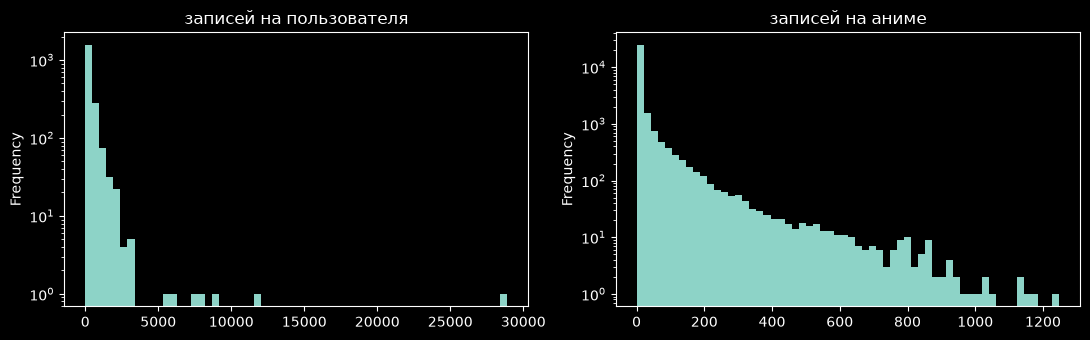

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
per_user.plot.hist(bins=60, log=True, ax=ax[0], title="записей на пользователя")
per_anime.plot.hist(bins=60, log=True, ax=ax[1], title="записей на аниме")
plt.tight_layout()

Длинный правый «хвост» означает, что немногие пользователи (киты) и немногие аниме (хиты) имеют огромную долю активности.

**Концентрация популярности.**

Сортируем аниме по числу записей и считаем, какая доля всех записей приходится на самый популярный 1% аниме. Чем больше доля, тем сильнее хиты доминируют, и тем сложнее модели рекомендовать что-то кроме них.

In [15]:
# Насколько концентрирована популярность: доля всех записей у топ-1% аниме
top = per_anime.sort_values(ascending=False)
top.head(int(len(top) * 0.01)).sum() / top.sum()

np.float64(0.2530975005506188)

Топ-1% аниме (около 297 штук из 29 711) держат 25% всех записей

**Влияние «китов».** То же самое для пользователей: какую долю всех записей создаёт самый активный 1% пользователей. Если доля большая, киты перетягивают на себя обучение и статистику популярности.

In [16]:
# 'Киты': доля записей у 1% самых больших профилей
big = per_user.sort_values(ascending=False)
big.head(int(len(big) * 0.01)).sum() / big.sum()

np.float64(0.15952973557342806)

Топ-1% пользователей (около 20 человек из 1996) создают 16% записей

Вывод:
- Хвосты длинные в обоих случаях, большинство аниме имеют единицы оценок. Один пользователь с 28 904 записями даёт 4,2% всех данных, это выброс, который нужно ограничить или рассмотреть отдельно.
- Простой popularity-baseline, вероятно, будет сильным, а редкие аниме трудно рекомендовать из-за нехватки данных.

## 4. Время

Перед любыми решениями про split: насколько `created_at` / `updated_at` похожи на реальную последовательность просмотров.

**Проверка времени.** Смотрим диапазон `created_at`, долю пользователей, у которых все записи созданы в один день (признак массового импорта), и разброс между первой и последней записью пользователя в днях. Всё это нужно, чтобы решить, можно ли делить данные по времени.

In [17]:
span = rates.groupby("user_id").created_at.agg(lambda s: (s.max() - s.min()).days)
single_day = rates.groupby("user_id").created_at.agg(lambda s: s.dt.date.nunique() == 1)
print("created_at range:", rates.created_at.min(), rates.created_at.max())
print("users with all rows on one day:", single_day.mean())
span.describe()

created_at range: 2012-03-30 12:29:00+00:00 2026-09-25 12:11:46.425224+00:00
users with all rows on one day: 0.2409819639278557


count    1996.000000
mean      838.462425
std      1178.256117
min         0.000000
25%         0.000000
50%       204.000000
75%      1510.750000
max      5138.000000
Name: created_at, dtype: float64

**Проверка порядка по времени на приквелах и сиквелах.** Если `created_at` отражает порядок просмотра, то у пользователя, у которого в списке есть и приквел, и его сиквел, приквел должен быть добавлен раньше. Берём из `anime_relations` связи `relation_kind == "sequel"` между аниме и для каждого пользователя, у которого есть обе части, сравниваем время добавления. Оставляем пары, где обе части `completed`, чтобы не смешивать с планами.

In [18]:
relations = pd.read_csv(DATA / "anime_relations.csv")
sequels = (
    relations[(relations.relation_kind == "sequel") & (relations.target_type == "Anime")]
    [["anime_id", "target_id"]]
    .drop_duplicates()
    .rename(columns={"anime_id": "prequel_id", "target_id": "sequel_id"})
)

cols = ["user_id", "anime_id", "status", "created_at"]
pairs = (
    sequels
    .merge(rates[cols].rename(columns={"anime_id": "prequel_id", "status": "status_p", "created_at": "created_p"}), on="prequel_id")
    .merge(rates[cols].rename(columns={"anime_id": "sequel_id", "status": "status_s", "created_at": "created_s"}), on=["sequel_id", "user_id"])
)
both_completed = pairs[(pairs.status_p == "completed") & (pairs.status_s == "completed")]

delta = both_completed.created_s - both_completed.created_p  # > 0: приквел добавлен раньше
pd.Series({
    "приквел добавлен раньше (больше чем на минуту)": (delta > pd.Timedelta("1min")).mean(),
    "обе части в пределах минуты": (delta.abs() <= pd.Timedelta("1min")).mean(),
    "приквел добавлен позже сиквела": (delta < -pd.Timedelta("1min")).mean(),
    "в один календарный день": (both_completed.created_p.dt.date == both_completed.created_s.dt.date).mean(),
    "число пар": len(both_completed),
})

приквел добавлен раньше (больше чем на минуту)         0.438343
обе части в пределах минуты                            0.409742
приквел добавлен позже сиквела                         0.151916
в один календарный день                                0.604813
число пар                                         122094.000000
dtype: float64

Вывод:

Диапазон created_at широкий (2012–2026), у 76% пользователей записи растянуты более чем на один день, медианный разброс 204 дня. Но 24% пользователей создали все записи за один день, а у медианного пользователя 59% записей созданы в один день, 41% всех записей приходится на пачки ≥50 записей за день. created_at показывает, когда запись добавлена в список, а не когда аниме смотрели, поэтому как время просмотра его использовать нельзя.

Временной сплит по created_at ненадёжен; для основного эксперимента используем разбиение без привязки ко времени (случайная доля позитивов на пользователя), а время пока оставляем как справочный признак.

## 5. Какие таблицы нужны модели

Не склеиваем всё в одну таблицу заранее. Для рекомендаций таблицы играют разные **роли**, и каждая роль соединяется с остальными только в момент, когда это нужно конкретному шагу.

| Роль | Таблицы | Зачем | Когда нужна |
| --- | --- | --- | --- |
| Взаимодействия (то, что предсказываем) | `user_anime_rates` | позитивы, прогресс, статусы; основа обучения и оценки | сразу, с baseline |
| Признаки аниме (content) | `anime_genres`, `genres` | у 46% аниме ≤2 оценок, жанры нужны, чтобы рекомендовать редкие аниме по сходству | с первой content-модели |
| Признаки аниме (дополнительные) | `anime_studios`, `studios`, `anime.description`, `anime.aired_on` (год), `anime.origin`, `anime.rating` | среди **всех** оценённых аниме студии есть у ~65%, описание у ~50%, но в каталоге после фильтра (≥5 `completed`) заполнены почти полностью: студии 99%, описание 99,7%, год и возрастной рейтинг 100%. Для редких аниме и для моделей с признаками (две башни, ранжирование) полезны | после жанров; текущие `anime.score`, `status`, `episodes_aired` как признаки нельзя (утечка из будущего) |
| Фильтр каталога | `anime.kind` и число оценок на аниме | убрать `music`, `cm`, `pv` и аниме с слишком малым числом оценок из кандидатов | при построении каталога кандидатов |
| Признаки пользователя | считаются **из** `user_anime_rates` (любимые жанры и т.п.) | профиль вкуса | при построении признаков |
| Сильный позитив | `user_favourites` (`category='animes'`) | 5990 записей, 98% уже есть в `rates`; новой информации мало, но это самый сильный явный сигнал | как контрольный срез метрик |
| Негатив / фильтр | `status='dropped'` из `user_anime_rates` | не рекомендовать уже брошенное; доля брошенного в Top-K как контрольная метрика. **Не** обучающий негатив: у 72% брошенных 0 просмотренных серий | фильтр и метрика с первого эксперимента |
| Правила и франшизы | `anime_chronology`, `anime_relations`, `anime.franchise` | не рекомендовать 3-й сезон без 1-го, схлопывать франшизу при реранжировании | этап реранжирования |
| События | `user_anime_history` | пары на 95% уже в `rates`; время событий так же сгруппировано в пачки, как `created_at`, поэтому для временного сплита не годится | отложить; возможно позже для числа серий и повторов |
| Служебные | `users` | доступность данных, группа когорты | при подготовке данных |

Время (`created_at`, `event_at`) в основной эксперимент **не берём**: записи создаются пачками, это дата заполнения списка, а не дата просмотра (раздел 4, проверка по `history` тоже).

Решение «берём / откладываем / не берём» принимаем по таблице выше и по покрытию ниже.

**Покрытие таблиц.** Загружаем остальные таблицы и считаем, насколько каждая нам пригодится: у какой доли оценённых аниме есть жанры, студии, описание и франшиза, и сколько данных из `history` и `favourites` уже есть в `rates`. Низкое покрытие значит, что признак будет неполным; высокое пересечение с `rates` значит, что таблица почти ничего не добавляет.

In [19]:
hist = pd.read_csv(DATA / "user_anime_history.csv", usecols=["user_id", "anime_id", "description"])
ag = pd.read_csv(DATA / "anime_genres.csv")
ast = pd.read_csv(DATA / "anime_studios.csv")
rel = pd.read_csv(DATA / "anime_relations.csv")
fav = pd.read_csv(DATA / "user_favourites.csv")
anime_full = pd.read_csv(DATA / "anime.csv", usecols=["anime_id", "description", "franchise", "kind", "season"])

In [20]:
rated_ids = set(rates.anime_id)
rated = anime_full[anime_full.anime_id.isin(rated_ids)]

pairs_rates = set(zip(rates.user_id, rates.anime_id))
pairs_hist = set(zip(hist.user_id, hist.anime_id))
fav_anime = fav[fav.category == "animes"]
pairs_fav = set(zip(fav_anime.user_id, fav_anime.target_id))

In [21]:
coverage = pd.Series({
    "жанры: доля аниме с >=1 жанром (среди оценённых)": rated.anime_id.isin(ag.anime_id).mean(),
    "студии: доля аниме с >=1 студией (среди оценённых)": rated.anime_id.isin(ast.anime_id).mean(),
    "описание непусто (среди оценённых)": rated.description.notna().mean(),
    "franchise непусто (среди оценённых)": rated.franchise.notna().mean(),
    "связи anime->anime среди всех relations": (rel.target_type == "Anime").mean(),
    "пары в history, которые есть и в rates": len(pairs_hist & pairs_rates) / len(pairs_hist),
    "пары в rates, у которых есть история": len(pairs_hist & pairs_rates) / len(pairs_rates),
    "избранные аниме, которые уже есть в rates": len(pairs_fav & pairs_rates) / len(pairs_fav),
})
coverage.round(3)

жанры: доля аниме с >=1 жанром (среди оценённых)      0.997
студии: доля аниме с >=1 студией (среди оценённых)    0.648
описание непусто (среди оценённых)                    0.500
franchise непусто (среди оценённых)                   0.531
связи anime->anime среди всех relations               0.780
пары в history, которые есть и в rates                0.948
пары в rates, у которых есть история                  0.960
избранные аниме, которые уже есть в rates             0.982
dtype: float64

In [22]:
# пометка: есть ли у аниме франшиза (пустой franchise = нет)
rated = rated.assign(has_franchise=rated.franchise.notna())

names = pd.read_csv(DATA / "anime.csv", usecols=["anime_id", "name", "russian"])

no_franchise = (
    rated[~rated.has_franchise]
    .merge(names, on="anime_id")
    .assign(n_rates=lambda d: d.anime_id.map(per_anime))
    .sort_values("n_rates", ascending=False)
)

no_franchise[["name", "russian", "kind", "n_rates"]].head(20)

AttributeError: 'DataFrame' object has no attribute 'has_franchise'

- Жанры: 99,7%. Почти у каждого оценённого аниме есть хотя бы один жанр. Это надёжный признак, на него можно опираться.
- Студии: 64,8%. У трети оценённых аниме студии нет, значит, признак «студия» для них неизвестен. Как основной он слабоват, как дополнительный годится.
- Описание: 50%. Половина оценённых аниме без текста. Если делать модель по описаниям, у половины каталога признака не будет.
- Из всех строк в anime_relations лишь 78% ведут на другое аниме, остальные 22% на мангу. Для нас эти 22% бесполезны (манги в каталоге аниме нет)
- История: 94,8% и 96%. 95% пар «пользователь–аниме» из history уже есть в rates, и у 96% пар из rates есть история. То есть эти две таблицы описывают почти одно и то же. Новой информации в history очень мало, и это ещё одна причина её не брать.
- Избранное: 98,2%. Почти все избранные аниме и так есть в списках пользователей. Остаётся ~2% (около сотни записей), которых в rates нет. Для основной модели это мало, но как контрольный сигнал избранное остаётся полезным.

**Типы аниме в каталоге.** Считаем, сколько оценённых аниме приходится на каждый тип (`tv`, `movie`, `music`, `cm`, `pv`…). Нужно решить, какие типы вообще рекомендовать: рекламные ролики и клипы, скорее всего, не нужны.

In [ ]:
# Тип аниме: нужны ли в каталоге рекламные ролики, клипы, PV?
rated.kind.value_counts(dropna=False)

- tv: сериал, выходивший по ТВ
- movie: полнометражный фильм
- ova: серии, выпущенные сразу на носителях, не по ТВ
- ona: выпущено сразу в интернете, без ТВ
- special: спецвыпуск, бонус к основному аниме
- tv_special: спецвыпуск, показанный по ТВ
- music: музыкальный клип
- cm: рекламный ролик (commercial)
- pv: промо-ролик к будущему аниме (promotional video)

In [ ]:
x = rates.merge(anime_full[["anime_id", "kind"]], on="anime_id")
x["kind"] = x.kind.fillna("нет")

by_kind = x.groupby("kind").agg(
    anime=("anime_id", "nunique"),      # сколько разных аниме этого типа
    rates=("anime_id", "size"),         # сколько записей всего
    completed_share=("status", lambda s: (s == "completed").mean()),
    explicit_share=("score", lambda s: (s > 0).mean()),  # доля записей с оценкой
)
by_kind["rates_per_anime"] = by_kind.rates / by_kind.anime
by_kind["share_of_all_rates"] = by_kind.rates / len(x)

by_kind.round(3).sort_values("rates", ascending=False)

Что делаем в итоге с данными?

- tv (65% записей, 52 записи на аниме), movie, ova, ona: основа данных, **оставляем**.
- cm, pv, нет: меньше 1% записей вместе, мало смысла, у нет почти нет явных оценок и completed (1,5%). **Выбрасываем**.
- music: 4067 аниме на 2% записей, ~3 записи на тайтл. Я не вижу особого смысла для пользователя в отдельном предложении посмотреть музыку...
- special, tv_special: много completed (74% и 70%), но это дополнения к основному аниме.

**Хвост каталога.** Считаем, какая доля аниме имеет 1–2 записи и сколько аниме набрали хотя бы 20. Редкие аниме модель не научится рекомендовать, потому что по ним слишком мало данных; это определит порог для каталога кандидатов.

In [ ]:
# 'Хвост' каталога: сколько аниме почти без взаимодействий
(per_anime <= 3).mean(), (per_anime >= 20).sum()

Хвост длинный (у 46% аниме 1–2 записи), редкие аниме модель всё равно не выучит.